# 10 · Combinar modelos y cambiar de modelo según el riesgo

**Punto de partida.** Cada modelo pasó por los mismos pasos (notebook 08) y tiene una mejor versión. Solos, le ganan poco al MDA (el mejor, LEAR en proporción con 64 nodos, 2.9%), pero no se equivocan exactamente en los mismos días. Además, cada uno aprovecha de forma distinta la información: las decisiones de la escalera mejoraron a unos y empeoraron a otros, de modo que cada versión se especializó en una parte del problema.

**Procedimiento.** Primero se ve por qué mezclar puede ayudar (quiénes se equivocan en días distintos y qué pasa al mezclar el MDA con un modelo que no lo ve). Después se prueban dos ideas que una mezcla de pesos fijos no cubre: pesos que se ajustan con el pasado y cambiar de modelo según el riesgo del día. Al final se prueban todas las mezclas de 2 y 3 modelos entre todas las versiones de la escalera y se elige el modelo final. Para elegir se usa el peor mes: el mayor cambio mensual del error contra el MDA en los seis meses de desarrollo (menos es mejor). Antes se usaba el error medio de todo el desarrollo; en el notebook 11 se comparan criterios y, como el peor mes resultó mejor, se volvió a correr toda la elección con él. Todo sigue en desarrollo; el test se evalúa en el notebook 11.

In [1]:
import os
for k in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'): os.environ[k] = '1'   # evita sobresuscripción en procesos paralelos
import sys, warnings, time, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from pml import plotstyle as ps
ps.aplicar()
FIG = ROOT / 'reports/figures'; REP = ROOT / 'reports'

from pml import features2 as f2, exp, referencias as rf, escalera, agregacion as ag, anomalias as an, picos, mezclas as mz
from pml.metrics import mae, gw_test, mae_por_bloque, peor_mes
R = rf.cargar()                                         # los pronósticos establecidos en los notebooks 05 a 08, desde caché
c0, cb, Y, X = R.c0, R.cb, R.Y, R.X
DEV, DIAS = exp.idx_dev(), exp.dias_eval(R.c0)
m = R.mae                                               # MAE de desarrollo, en MXN/MWh
CACHE = ROOT / 'data/processed/exp_cache'
tabla = lambda filas, archivo: (lambda T: (display(T), T.to_csv(REP / archivo)))(exp.comparar(Y, filas, X, registrar_como='nb11'))

## 1. Las piezas: la mejor versión de cada modelo

In [2]:
# La mejor versión de cada modelo en la escalera del notebook 08: la de menor peor mes (a igualdad, la más sencilla)
PASOS = escalera.cargar_pasos(R)
TRAY = escalera.trayectoria(PASOS, Y, X, DEV)
MEJOR = escalera.mejor_version(PASOS, TRAY)
PIEZAS = {k: P for k, (paso, P) in MEJOR.items()}
pm = lambda P: peor_mes(Y, X, P, DEV)                       # el criterio de elección: el peor cambio mensual contra el MDA (meses de desarrollo)
T = pd.DataFrame({k: {'mejor versión': paso, 'MAE (MXN/MWh)': m(PASOS[k][paso]), 'vs MDA (%)': 100 * (m(PASOS[k][paso]) / m(X) - 1), 'peor mes (%)': pm(PASOS[k][paso])} for k, (paso, _) in MEJOR.items()}).T
T.loc['MDA'] = ['(referencia)', m(X), 0.0, 0.0]
for c_ in ('MAE (MXN/MWh)', 'vs MDA (%)', 'peor mes (%)'): T[c_] = T[c_].astype(float).round(1)
display(T); T.to_csv(REP / '10_piezas_dev.csv')

,mejor versión,MAE (MXN/MWh),vs MDA (%),peor mes (%)
LEAR,con MDA,219.2,-1.1,0.2
LEAR en proporción,+ nodos,215.2,-2.9,-0.8
GB,+ modelado estadístico,218.4,-1.5,1.8
TiDE,con MDA,219.7,-0.8,0.9
red sin MDA,PCA,236.7,6.8,74.3
MDA,(referencia),221.6,0.0,0.0


La mejor versión de cada modelo es la de menor peor mes en desarrollo (si una más sencilla queda a menos de 0.5 puntos, la más sencilla):

- **LEAR:** la base sin nodos (219.2, peor mes +0.2%); con 64 nodos queda casi igual (218.8).
- **LEAR en proporción:** con 64 nodos (215.2, −2.9% contra el MDA; peor mes −0.8%), el mejor modelo individual y el único que le gana al MDA en todos los meses.
- **GB:** con 64 nodos y el modelado estadístico (218.4, −1.5%; peor mes +1.8%).
- **TiDE:** la base sin nodos (219.7; peor mes +0.9%); con nodos empeora.
- **Red sin MDA:** con PCA (236.7, 6.8% peor que el MDA; peor mes +74.3%). En el test es la que peor se porta de sus cuatro versiones (notebook 08).

Las versiones individuales quedan entre 1% y 3% mejores que el MDA en el promedio. La red sin MDA solo tiene sentido como pieza de mezcla.

## 2. ¿Quiénes se equivocan en días distintos?

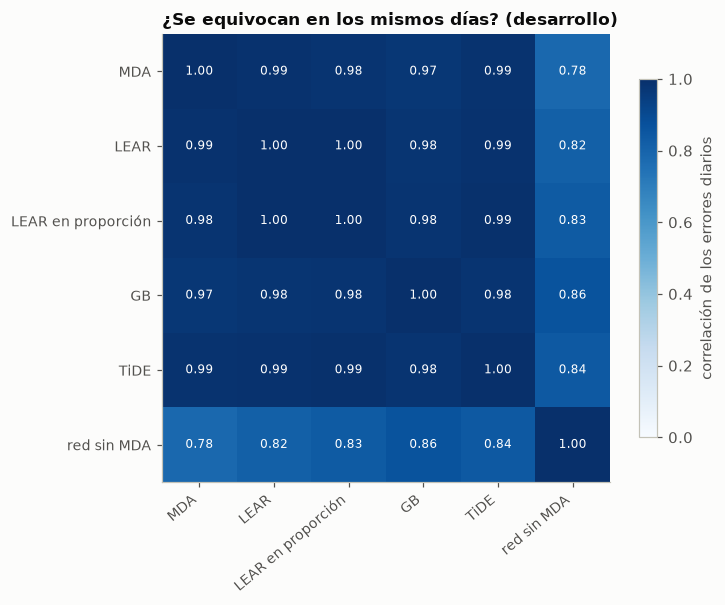

In [3]:
# ¿Quiénes se equivocan en los mismos días? Correlación entre los errores diarios (MTR − pronóstico, promedio de las 24 horas) de cada pieza
PZ = {'MDA': X, **PIEZAS}
E = pd.DataFrame({k: (Y - P).loc[DEV].mean(axis=1) for k, P in PZ.items()})
C = E.corr()
fig, ax = plt.subplots(figsize=(7, 5.6))
im = ax.imshow(C.values, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(C)), C.columns, rotation=40, ha='right', fontsize=9); ax.set_yticks(range(len(C)), C.index, fontsize=9); ax.grid(False)
for i in range(len(C)):
    for j in range(len(C)): ax.text(j, i, f'{C.values[i, j]:.2f}', ha='center', va='center', fontsize=8, color='white' if C.values[i, j] > 0.6 else '#0b0b0b')
fig.colorbar(im, ax=ax, shrink=0.8, label='correlación de los errores diarios'); ax.set_title('¿Se equivocan en los mismos días? (desarrollo)')
fig.tight_layout(); fig.savefig(FIG / '10_correlacion_errores.png'); plt.show()

Los errores diarios de los modelos que corrigen al MDA se parecen casi por completo entre sí y al MDA (correlaciones de 0.98 a 1.00), porque corrigen poco. La red sin MDA se equivoca bastante distinto (0.78 a 0.84).

La red sin MDA es la pieza que más puede aportar a una mezcla. Entre los demás, la diferencia es pequeña, aunque LEAR y el GB usan información distinta: LEAR vive del MDA y el GB de la historia del MTR (notebook 07).

## 3. Mezclar el MDA con un modelo que no lo ve

,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0
MAE desarrollo,236.7,229.5,223.3,218.2,214.4,211.9,210.9,211.2,212.7,216.1,221.6


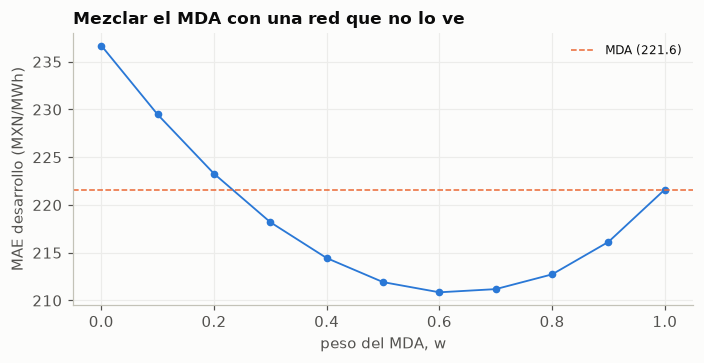

w con menor error en desarrollo: 0.6


In [4]:
# Mezclar el MDA con un modelo que no lo ve: pronóstico = w·MDA + (1 − w)·red sin MDA
ws = np.round(np.arange(0, 1.01, 0.1), 1)
CW = pd.Series({w: m(w * X + (1 - w) * PIEZAS['red sin MDA']) for w in ws})
display(CW.round(1).to_frame('MAE desarrollo').T)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(CW.index, CW.values, color=ps.AZUL, marker='o', ms=4); ax.axhline(m(X), color=ps.NARANJA, lw=1, ls='--', label=f'MDA ({m(X):.1f})')
ax.set_xlabel('peso del MDA, w'); ax.set_ylabel('MAE desarrollo (MXN/MWh)'); ax.legend(fontsize=8); ax.set_title('Mezclar el MDA con una red que no lo ve')
fig.tight_layout(); fig.savefig(FIG / '10_peso_mda.png'); plt.show()
print('w con menor error en desarrollo:', CW.idxmin())

Mezclando el MDA con la red sin MDA, el mejor peso del MDA es 0.6: 210.9, 4.8% menos error que el MDA solo. Con 0.8 (el reparto fijado de antemano) queda en 212.7. Solo la red (peso 0) tiene 236.7.

La red sin MDA no sirve sola, pero mezclada con el MDA le quita parte de su error, porque se equivocan en días distintos.

## 4. Pesos que se aprenden con el pasado

peso medio de cada pieza en desarrollo: {'MDA': 0.29, 'LEAR en proporción': 0.38, 'GB': 0.05, 'red sin MDA': 0.26, 'TiDE': 0.02}


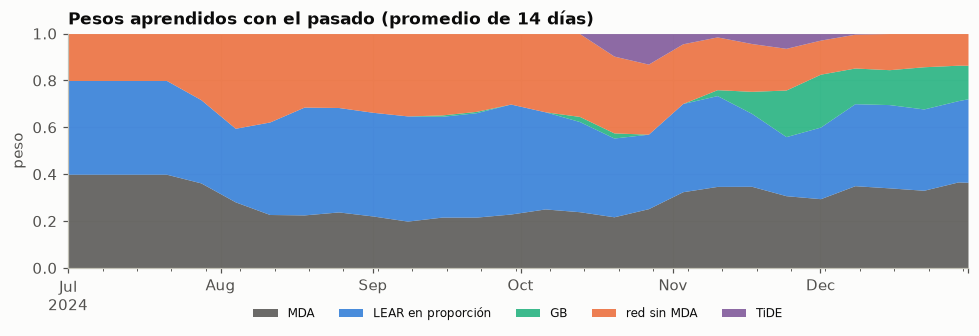

pesos aprendidos: 209.3 (-5.6%), peor mes -0.9% | reparto fijo 0.4 / 0.4 / 0.2: 209.6, peor mes -1.8%


In [5]:
# Pesos que se aprenden con el pasado: cada semana, los pesos (no negativos, suman 1) que habrían minimizado el MAE de las últimas 8 semanas con MTR
# ya publicado (hasta d−8), encogidos a la mitad hacia el reparto 0.4 / 0.4 / 0.2. Una sola configuración, fijada de antemano
L, LL, GB, RS = PIEZAS['LEAR'], PIEZAS['LEAR en proporción'], PIEZAS['GB'], PIEZAS['red sin MDA']
BASE_APR = 0.4 * X + 0.4 * LL + 0.2 * RS                                  # el reparto fijo del que parten los pesos
EXPERTOS = {'MDA': X, 'LEAR en proporción': LL, 'GB': GB, 'red sin MDA': RS, 'TiDE': PIEZAS['TiDE']}
APR, PESOS = ag.ventana_lad({k: v.loc[DIAS] for k, v in EXPERTOS.items()}, Y, DIAS, {'MDA': 0.4, 'LEAR en proporción': 0.4, 'red sin MDA': 0.2}, ventana=56, encoge=0.5)
print('peso medio de cada pieza en desarrollo:', PESOS.loc[DEV].mean().round(2).to_dict())
fig, ax = plt.subplots(figsize=(9, 3.2)); PESOS.loc[DEV].rolling(14, min_periods=1).mean().plot.area(ax=ax, color=[ps.GRIS, ps.AZUL, ps.AQUA, ps.NARANJA, '#7a5195'], alpha=0.85, lw=0)
ax.set_ylim(0, 1); ax.set_ylabel('peso'); ax.set_title('Pesos aprendidos con el pasado (promedio de 14 días)'); ax.legend(fontsize=8, ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.12))
fig.tight_layout(); fig.savefig(FIG / '10_pesos_aprendidos.png', bbox_inches='tight'); plt.show()
print(f'pesos aprendidos: {m(APR):.1f} ({100 * (m(APR) / m(X) - 1):+.1f}%), peor mes {pm(APR):+.1f}% | reparto fijo 0.4 / 0.4 / 0.2: {m(BASE_APR):.1f}, peor mes {pm(BASE_APR):+.1f}%')

Los pesos aprendidos con las últimas 8 semanas conocidas dan 209.3 en error medio (−5.6%), pero su peor mes (−0.9%) queda 0.9 puntos por encima del reparto fijo del que parten (0.4 MDA, 0.4 LEAR en proporción, 0.2 red sin MDA; −1.8%). En desarrollo repartieron en promedio 0.38 a LEAR en proporción, 0.29 al MDA, 0.26 a la red sin MDA, 0.05 al GB y 0.02 a TiDE.

Los pesos que se aprenden terminan cerca de los fijos y no mejoran el peor mes. El pasado reciente no dice mucho sobre qué pieza será mejor mañana, así que no se usan.

## 5. Cambiar de modelo según el riesgo del día

In [6]:
# Cambiar de modelo según el riesgo del día. El riesgo es el percentil del máximo del MDA de mañana frente a los últimos tres meses (solo información de d−1;
# es el puntaje que mejor ordena los días anómalos entre los que no usan el MTR, notebook 09). Tranquilo: la mezcla de LEAR en proporción y GB.
# Riesgoso: la mezcla conservadora 0.8·MDA + 0.2·red sin MDA
mx = X.max(axis=1)
PCT = an.percentil_historico(mx.reindex(DIAS), mx.dropna())
AGR, CON = ((LL + GB) / 2).loc[DIAS], (0.8 * X + 0.2 * RS).loc[DIAS]
def cambia(q):
    tranquilo = (PCT.reindex(AGR.index) <= q).values[:, None]
    return pd.DataFrame(np.where(tranquilo, AGR.values, CON.values), index=AGR.index, columns=AGR.columns)
RIESGO = {f'cambia a la conservadora si el riesgo supera {q:.0%}': cambia(q) for q in (0.8, 0.9, 0.95)}
RIESGO['pasa gradualmente de una a otra según el riesgo'] = CON + (1 - PCT.reindex(AGR.index)).values[:, None] * (AGR - CON)
yp = picos.etiqueta(c0).reindex(DEV) == 1
print(f'percentil de riesgo promedio en desarrollo: días con pico {PCT.reindex(DEV)[yp].mean():.2f} | sin pico {PCT.reindex(DEV)[~yp].mean():.2f}')
print('días de desarrollo que superan cada corte:', {f'{q:.0%}': int((PCT.reindex(DEV) > q).sum()) for q in (0.8, 0.9, 0.95)}, f'de {len(DEV)}')
print(f'solo la mezcla agresiva {m(AGR):.1f} (peor mes {pm(AGR):+.1f}%) | solo la conservadora {m(CON):.1f} (peor mes {pm(CON):+.1f}%)')
for k, P in RIESGO.items(): print(f'{k}: {m(P):.1f} (peor mes {pm(P):+.1f}%)')

percentil de riesgo promedio en desarrollo: días con pico 0.35 | sin pico 0.31
días de desarrollo que superan cada corte: {'80%': 1, '90%': 1, '95%': 0} de 184
solo la mezcla agresiva 212.8 (peor mes -1.6%) | solo la conservadora 212.7 (peor mes -1.5%)
cambia a la conservadora si el riesgo supera 80%: 212.7 (peor mes -1.6%)
cambia a la conservadora si el riesgo supera 90%: 212.7 (peor mes -1.6%)
cambia a la conservadora si el riesgo supera 95%: 212.8 (peor mes -1.6%)
pasa gradualmente de una a otra según el riesgo: 212.1 (peor mes -2.2%)


El puntaje de riesgo es el percentil del máximo del MDA de mañana frente a los últimos tres meses. En desarrollo casi no se activa: solo un día supera el corte de 80% y ninguno el de 95%, y el percentil promedio de los días con pico (0.35) es casi igual al de los días sin pico (0.31). La mezcla agresiva (LEAR en proporción + GB, 212.8; peor mes −1.6%) y la conservadora (0.8·MDA + 0.2·red sin MDA, 212.7; −1.5%) tienen casi el mismo error, y cambiar de una a otra en los días de riesgo no cambia nada (212.7 a 212.8). La variante gradual, que pasa de una a otra según el percentil, mejora un poco (212.1; −2.2%), pero porque suma peso de la mezcla conservadora, no porque reconozca días de riesgo.

Es lo que ya se vio en el notebook 09: en el desarrollo los picos no se anuncian en el MDA del día anterior, así que no hay días de riesgo que el puntaje reconozca. Cambiar de modelo según el riesgo no se usa; el riesgo queda como información para quien use el pronóstico.

## 6. Mezclas de 2 y 3 modelos entre todas las versiones

Cada versión de la escalera aprovecha la información de manera distinta: las decisiones (más nodos, exógenas, modelado estadístico, todas las variables, PCA) mejoraron a unos modelos y empeoraron a otros. Combinar versiones de modelos diferentes aprovecha esas representaciones internas distintas, y la mezcla puede decidir desde las perspectivas en que cada una se especializó al aprender.

Se prueban todas las combinaciones de 1, 2 o 3 de los 28 pronósticos disponibles (el MDA y cada versión de cada modelo de la escalera), con pesos múltiplos de 0.1 que suman 1; por ejemplo, 0.3·TiDE con MDA + 0.7·GB con todas las variables, o 0.5·red sin MDA con PCA + 0.2·GB con MDA + 0.3·LEAR con PCA. Son 121,366 candidatas (3,402 parejas y 117,936 ternas). Las mezclas a mano, como acercar un modelo al MDA (MDA + modelo) o promediar dos modelos, son casos particulares de esta búsqueda. Se califican con el peor mes de desarrollo y se elige la de menor calificación. No se entrena nada nuevo: son combinaciones de pronósticos ya hechos, calculadas en el servidor.

In [7]:
# Mezclas de 2 y 3 modelos entre todas las versiones de la escalera: cada candidata combina 1, 2 o 3 pronósticos (el MDA o cualquier versión de
# cualquier modelo) con pesos múltiplos de 0.1 que suman 1. Se calcularon en el servidor (src/pml/servidor.py mezclas:todas) y se leen de caché.
# Aquí solo se usan los meses de desarrollo
FC = {'MDA': X, **{f'{k} · {p}': P for k, d in PASOS.items() for p, P in d.items() if P is not None}}
MZ = mz.evaluar(Y, X, FC, DEV, exp.idx_test())
NOM, CANDS = MZ['nombres'], MZ['cands']
CAL = mz.calificaciones(MZ['mensual'].iloc[:, :6], MZ['desarrollo'])          # calificación con cada criterio, solo meses de desarrollo
orden = np.argsort(CAL['peor mes'].values)                                   # el criterio de elección: el peor mes
print(f'{len(NOM)} pronósticos, {len(CANDS):,} candidatas ({sum(len(c[0]) == 2 for c in CANDS):,} parejas y {sum(len(c[0]) == 3 for c in CANDS):,} ternas)')
TOP = pd.DataFrame({'mezcla': [mz.nombre(NOM, CANDS[r]) for r in orden[:10]], 'peor mes (%)': CAL['peor mes'].values[orden[:10]],
                    'desarrollo vs MDA (%)': MZ['desarrollo'].values[orden[:10]]}).round(1)
display(TOP); TOP.to_csv(REP / '10_mezclas_mejores_dev.csv', index=False)
FINAL_N = mz.nombre(NOM, CANDS[orden[0]])
ARR = np.stack([FC[k].loc[DIAS].values for k in NOM])
MEZCLA = pd.DataFrame(mz.pronostico(ARR, CANDS[orden[0]]), index=DIAS, columns=X.columns)
print(f'la mezcla elegida: {FINAL_N} | desarrollo {100 * (m(MEZCLA) / m(X) - 1):+.1f}% | peor mes {pm(MEZCLA):+.1f}%')
# Lo que se evalúa en el notebook 11: las piezas, el MDA y el modelo final
POOL = {**PIEZAS, 'MDA': X, FINAL_N: MEZCLA}
pickle.dump(dict(pool=POOL, final=FINAL_N, pasos={k: p for k, (p, _) in MEJOR.items()}), open(CACHE / 'nb11_conjunto_final.pkl', 'wb'))

28 pronósticos, 121,366 candidatas (3,402 parejas y 117,936 ternas)


,mezcla,peor mes (%),desarrollo vs MDA (%)
0,0.5·LEAR en proporción · + nodos + 0.4·GB · to...,-3.8,-5.4
1,0.6·LEAR en proporción · + nodos + 0.3·GB · to...,-3.5,-5.5
2,0.6·LEAR en proporción · + modelado estadístic...,-3.5,-5.5
3,0.5·LEAR en proporción · + modelado estadístic...,-3.3,-6.2
4,0.5·LEAR en proporción · + modelado estadístic...,-3.3,-5.7
5,0.6·LEAR · + nodos + 0.3·GB · todas las variab...,-3.3,-4.8
6,0.5·LEAR en proporción · con MDA + 0.3·GB · to...,-3.3,-5.9
7,0.7·LEAR · con MDA + 0.2·GB · todas las variab...,-3.3,-4.5
8,0.6·LEAR en proporción · con MDA + 0.2·GB · to...,-3.3,-5.9
9,0.6·LEAR · con MDA + 0.3·GB · todas las variab...,-3.3,-4.7


la mezcla elegida: 0.5·LEAR en proporción · + nodos + 0.4·GB · todas las variables + 0.1·red sin MDA · todas las variables | desarrollo -5.4% | peor mes -3.8%


La mezcla elegida es **0.5·LEAR en proporción con nodos + 0.4·GB con todas las variables + 0.1·red sin MDA con todas las variables**: en desarrollo le gana al MDA en los seis meses, con un peor mes de −3.8% y un error medio de −5.4% (209.6). Las diez mejores según el peor mes son mezclas parecidas, de LEAR o LEAR en proporción con el GB con todas las variables (peor mes de −3.8% a −3.3%).

La mezcla junta tres maneras distintas de aprender: LEAR en proporción, que corrige al MDA y aprovecha los nodos; el GB, que elige entre todas las variables, y una pequeña parte de la red sin MDA, que no ve el MDA y se equivoca en días distintos. Ese 10% de la red sin MDA ayuda porque, mezclado, sus errores compensan los de las otras piezas, aunque sola pierda contra el MDA.

## Decisiones

- Mezclar ayuda: los modelos se equivocan en días algo distintos y, mezclados, ninguna pieza pierde mucho en un mes porque las demás la compensan.
- Los pesos aprendidos con el pasado y el cambio de modelo según el riesgo no mejoran a las mezclas de pesos fijos.
- Entre todas las mezclas de 2 y 3 modelos, el modelo final es 0.5·LEAR en proporción con nodos + 0.4·GB con todas las variables + 0.1·red sin MDA con todas las variables, elegido con el peor mes. Se evalúa en el notebook 11.